In [223]:
import torch
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
import torch.nn.functional as F
import random

In [233]:
words = open("names.txt","r").read().splitlines()
words[:5]
len(words)

32033

In [234]:
chars = sorted(list(set(''.join(words))))
chars
stoi = {s:i+1 for (i,s) in enumerate(chars)}
stoi['.']=0
itos = {i:s for (s,i) in stoi.items()}
itos

{1: 'a',
 2: 'b',
 3: 'c',
 4: 'd',
 5: 'e',
 6: 'f',
 7: 'g',
 8: 'h',
 9: 'i',
 10: 'j',
 11: 'k',
 12: 'l',
 13: 'm',
 14: 'n',
 15: 'o',
 16: 'p',
 17: 'q',
 18: 'r',
 19: 's',
 20: 't',
 21: 'u',
 22: 'v',
 23: 'w',
 24: 'x',
 25: 'y',
 26: 'z',
 0: '.'}

In [235]:
# block_size =3
# x,y =[],[]
# for w in words:
#     # print(w)
#     context =[0]*block_size
    
#     for char in w +'.':
#         idx =stoi[char]
#         y.append(idx)
#         x.append(context)
#         # print( ''.join(itos[i] for i in context), '--->', itos[idx])
#         context= context[1:]+[idx]
#         # print(context)
# xs = torch.tensor(x)
# ys = torch.tensor(y)

In [257]:
def build_dataset(words):
    block_size =3
    x,y =[],[]
    for w in words:
        # print(w)
        context =[0]*block_size
        
        for char in w +'.':
            idx =stoi[char]
            y.append(idx)
            x.append(context)
            # print( ''.join(itos[i] for i in context), '--->', itos[idx])
            context= context[1:]+[idx]
            # print(context)
    xs = torch.tensor(x)
    ys = torch.tensor(y)
    return xs,ys

random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

xtr , ytr = build_dataset(words[:n1]) 
xval , yval = build_dataset(words[n1:n2]) 
xtest , ytest = build_dataset(words[n2:]) 


    

In [258]:
# # xs
# # # xs.shape
# # c[xs].shape
# embd = c[xs]
# embd.shape

In [259]:
c= torch.randn((27,10),requires_grad=True)

w1 = torch.randn((30,300) , requires_grad=True)
b1 = torch.randn((300),requires_grad=True)
w2 =torch.rand((300,27),requires_grad=True)
b2 = torch.randn(27,requires_grad=True)
parameters =[c,w1,b1,w2,b2]

In [260]:
# emd1=[]
# for i in (embd):
#     x=[]
#     for j in i :
#         x+=j
#     emd1.append(torch.tensor(x))
    
# embd=torch.tensor(emd1)

# # torch.cat(embd[:,0,
# embd =torch.cat(torch.unbind(embd,1),1).shape
# embd
        

In [262]:
lossi =[]
steps =[]
for i in range(30000):
    
    #mini batch 
    ix = torch.randint(0,xtr.shape[0],(32,))
    
    
    embd = c[xtr[ix]]
    # forward pass
    h= torch.tanh(embd.view(-1,30)@ w1 +b1)
    h.shape
    logits = (h@w2+b2)
    logits.shape
    loss =F.cross_entropy(logits,ytr[ix])
    # print(f'{i}: {loss}')
    # backward pass
    for p in parameters:
        p.grad=None

    loss.backward()
    for p in parameters:
        p.data+= -0.1*p.grad
    lossi.append(loss.item())
    steps.append(i)
print(loss)

tensor(2.2766, grad_fn=<NllLossBackward0>)


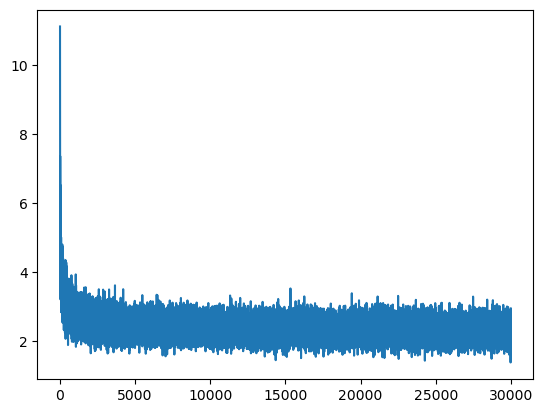

In [263]:
plt.plot(steps,lossi)

In [265]:
embd = c[xtr]
# forward pass
h= torch.tanh(embd.view(-1,30)@ w1 +b1)
h.shape
logits = (h@w2+b2)
logits.shape
loss =F.cross_entropy(logits,ytr)
loss.item()

2.255472421646118

In [266]:
embd = c[xval]
# forward pass
h= torch.tanh(embd.view(-1,30)@ w1 +b1)
h.shape
logits = (h@w2+b2)
logits.shape
loss =F.cross_entropy(logits,yval)
loss.item()

2.307509660720825

split data into training_Data 80% validation 10%  test split 10%

In [ ]:
# counts = logits.exp()
# prob = counts/counts.sum(1, keepdim=True)
# prob.shape
# prob[0].sum()
# loss =-prob[torch.arange(16),y].log().mean()
# loss
# loss =F.cross_entropy(logits,ys)

# loss.backward()

# ix = torch.randint(0,xs.shape[0],(32,))
# ix

tensor([149244, 145663,  12987,  31816, 192187, 178816, 176922, 224240,  76907,
        221778,  14006,  98942,   4531,   9864,  22607,  78045,  24475,  31362,
         80816,  75228, 193713, 154225, 164421, 202291,   1705, 131543,  18905,
        199720, 162632, 186157, 136509, 140266])

tensor(5.6470)